In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sympy import *


In [37]:
x, y, z, phi, psi, theta = symbols('x y z phi psi theta', real = True)

xdot = x.diff(x)
ydot = y.diff(y)
zdot = z.diff(z)
phidot = phi.diff(phi)
thetadot = theta.diff(theta)
psidot = psi.diff(psi)



In [38]:
m = symbols('m', real = True)
g = 9.81
L1, L2, L3, L4 = symbols('L1 L2 L3 L4', real = True)
L = L1 + L2 + L3 + L4
m = 0.85578 #kg
mmot = 0.029
mdrone = m-4*mmot
#assume that the drone is going to be modeled as a rectangular box, with three circular drone parameters. Set the origin to the bottom of the drone frame. We are ignoring the drone frame legs.
#Discounting/negligible hobbywing
Wrect = .096
Lrect = .180
Hdrone = 0.052
Hsky= 0.008
Hbattery = .024
Hbee = 0.0161
Hchannel = 0.01502

H = Hsky + Hbattery + Hbee + Hchannel + Hdrone

Wmot = 0.028
Lmot = 0.028
Hmot = 0.024

Axdrone = H*Lrect
Aydrone = H*Wrect

Axmot = Lmot*Hmot
Aymot = Wmot*Hmot

dx = .450/2
dy = .450/2
dz1 = .052/2
dz2 = .052+Hmot/2

Ixx_body = (1/12)*mdrone*(Wrect**2 + H**2)
Iyy_body = (1/12)*mdrone*(Lrect**2 + H**2)
Izz_body = (1/12)*mdrone*(Lrect**2 + Wrect**2)

Ixx_motor = (1/12)*mmot*(Wmot**2 + Hmot**2)
Iyy_motor = (1/12)*mmot*(Lmot**2 + Hmot**2)
Izz_motor = (1/12)*mmot*(Lmot**2 + Wmot**2)

x_motor = np.array([dx, 0, -dx, 0])
y_motor = np.array([0, dy, 0, -dy])
z_motor_positions = np.array([dz2]*4)

z_com = (
    mdrone*dz1 + mmot*np.sum(z_motor_positions)
) / m

# Parallel-axis theorem
Ixx = Ixx_body + mdrone*(dz1-z_com)**2 + np.sum(
    Ixx_motor + mmot*(y_motor**2 + (z_motor_positions-z_com)**2)
)

Iyy = Iyy_body + mdrone*(dz1-z_com)**2 + np.sum(
    Iyy_motor + mmot*(x_motor**2 + (z_motor_positions-z_com)**2)
)

Izz = Izz_body + np.sum(
    Izz_motor + mmot*(x_motor**2 + y_motor**2)
)

print("Ixx =", Ixx)
print("Iyy =", Iyy)
print("Izz =", Izz)

Ixx = 0.0044793483211581645
Iyy = 0.005908603281158165
Izz = 0.008453214373333334


Differential equatoins

In [39]:
# xddot = L/m*(cos(phi)*sin(theta)*cos(psi) + sin(phi)*sin(psi))
# yddot = L/m*(cos(phi)*sin(theta)*sin(psi) - sin(phi)*cos(psi))
# zddot = L/m*(cos(phi)*cos(theta))-g

# phiddot = phidot + thetadot*cos(phi)*tan(theta) + psidot*cos(phi)*sin(theta)
# thetadot = thetadot*(cos(phi)) -psidot*sin(phi)
# psiddot = thetadot*(sin(phi)/cos(theta)) + psidot*(cos(phi)/cos(theta))


# #from 7,222 rpm to rad/s = 756.28 rad/s


D = 0.0127 #propeller diameter
C_t= 0.8
rho = 1.225
kf = rho*C_t*D**4/(4*np.pi**2)
W = 4.88
km = (m*g)/np.sqrt(W)

In [40]:

def drone_dynamics(t, state, Omega):

    x, y, z = state[0:3]
    vx, vy, vz = state[3:6]
    phi, theta, psi = state[6:9]
    phidot, thetadot, psidot = state[9:12]


    O1, O2, O3, O4 = Omega

    L1 = kf * O1**2
    L2 = kf * O2**2
    L3 = kf * O3**2
    L4 = kf * O4**2
    L = L1 + L2 + L3 + L4

    tau_x = .450/2 * (L2 - L4)
    tau_y = .450/2* (L3 - L1)
    tau_z = km*(O1**2 - O2**2 + O3**2 - O4**2)

    dx = vx
    dy = vy
    dz = vz

    vdx = L/m*(np.cos(phi)*np.sin(theta)*np.cos(psi) + np.sin(phi)*np.sin(psi))
    vdy = L/m*(np.cos(phi)*np.sin(theta)*np.sin(psi) - np.sin(phi)*np.cos(psi))
    vdz = L/m*(np.cos(phi)*np.cos(theta))-g

    phiddot = phidot + thetadot*np.cos(phi)*np.tan(theta) + psidot*np.cos(phi)*np.sin(theta)
    thetadot = thetadot*(np.cos(phi)) -psidot*np.sin(phi)
    psiddot = thetadot*(np.sin(phi)/np.cos(theta)) + psidot*(np.cos(phi)/np.cos(theta))

    dp = (tau_x + (Iyy-Izz)*thetadot*psidot) / Ixx

    dq = (tau_y + (Izz-Ixx)*phidot*psidot) / Iyy

    dr = (tau_z + (Ixx-Iyy)*phidot*thetadot) / Izz

    return [
        dx, dy, dz,
        vdx, vdy, vdz,
        phidot, thetadot, psidot,
        dp, dq, dr
    ]
Omega_hover = np.sqrt(m*g/(4*kf))

Omega = [Omega_hover]*4

state0 = [
    0, 0, 1,
    0, 0, 0,
    0, 0, 0,
    0, 0, 0
]


t_span = (0, 120)

t_eval = np.linspace(0, 120, 1000)

sol_q1 = solve_ivp(
    drone_dynamics,
    t_span,
    state0,
    args=(Omega,),
    t_eval=t_eval
)




#Question 1

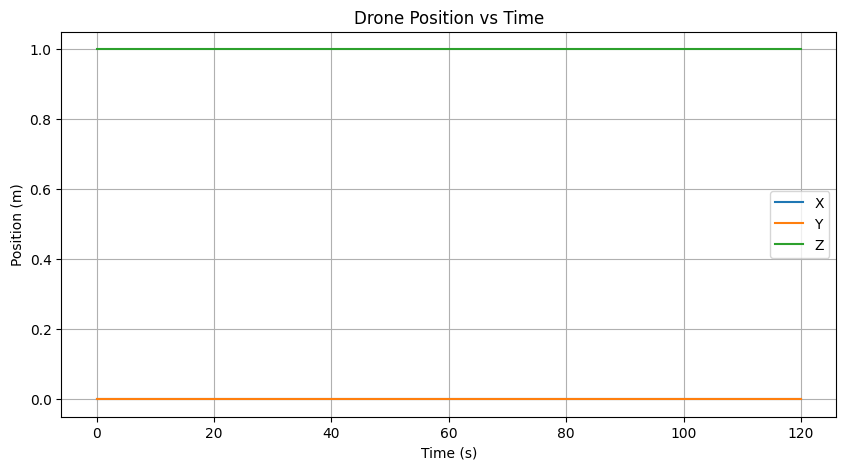

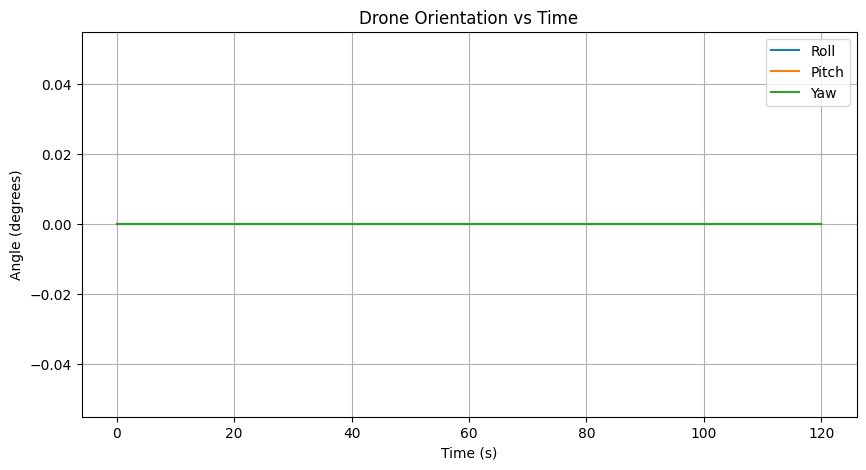

In [41]:
plt.figure(figsize=(10,5))
plt.plot(sol_q1.t, sol_q1.y[0], label="X")
plt.plot(sol_q1.t, sol_q1.y[1], label="Y")
plt.plot(sol_q1.t, sol_q1.y[2], label="Z")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Drone Position vs Time")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(sol_q1.t, np.rad2deg(sol_q1.y[6]), label="Roll")
plt.plot(sol_q1.t, np.rad2deg(sol_q1.y[7]), label="Pitch")
plt.plot(sol_q1.t, np.rad2deg(sol_q1.y[8]), label="Yaw")

plt.xlabel("Time (s)")
plt.ylabel("Angle (degrees)")
plt.title("Drone Orientation vs Time")
plt.legend()
plt.grid()
plt.show()

#Question 2

In [42]:
Kp_pos = 2.0
Kd_pos = 2.0

def position_controller(state, t):

    x, y, z = state[0:3]
    vx, vy, vz = state[3:6]

    xd, yd, zd, vxd, vyd, vzd, axd, ayd, azd = situation2(t)

    ax_cmd = axd + Kp_pos*(xd-x) + Kd_pos*(vxd-vx)
    ay_cmd = ayd + Kp_pos*(yd-y) + Kd_pos*(vyd-vy)
    az_cmd = azd + Kp_pos*(zd-z) + Kd_pos*(vzd-vz)

    return ax_cmd, ay_cmd, az_cmd

R = 2.0
v = 0.5
omega = v/R

def situation2(t):
    x = R*np.cos(omega*t)
    y = R*np.sin(omega*t)
    z = 1.0

    vx = -R*omega*np.sin(omega*t)
    vy = R*omega*np.cos(omega*t)
    vz = 0.0

    ax = -R*omega**2*np.cos(omega*t)
    ay = -R*omega**2*np.sin(omega*t)
    az = 0.0

    return x, y, z, vx, vy, vz, ax, ay, az

arm = 0.450/2

B = np.array([
    [kf, kf, kf, kf],
    [0, kf*arm, 0, -kf*arm],
    [-kf*arm, 0, kf*arm, 0],
    [km, -km, km, -km]
])

def rotor_mixer(T, tau_x, tau_y, tau_z):

    commands = np.array([T, tau_x, tau_y, tau_z])

    omega_squared = np.linalg.solve(B, commands)

    omega_squared = np.maximum(omega_squared, 0)

    return np.sqrt(omega_squared)

    psi_des = 0.0




In [43]:
def drone_dynamics(t, state):

    x, y, z = state[0:3]
    vx, vy, vz = state[3:6]
    phi, theta, psi = state[6:9]
    phidot, thetadot, psidot = state[9:12]

    ax_cmd, ay_cmd, az_cmd = position_controller(state, t)

    psi_des = 0.0
    T_des = m * (az_cmd + g) / (np.cos(phi) * np.cos(theta))
    phi_des = (ax_cmd * np.sin(psi_des) - ay_cmd * np.cos(psi_des)) / g
    theta_des = (ax_cmd * np.cos(psi_des) + ay_cmd * np.sin(psi_des)) / g

    tau_x = (phi_des - phi) -  phidot
    tau_y = (theta_des - theta) - thetadot
    tau_z =  (psi_des - psi) - psidot

    O1, O2, O3, O4 = rotor_mixer(T_des, tau_x, tau_y, tau_z)

    L1 = kf * O1**2
    L2 = kf * O2**2
    L3 = kf * O3**2
    L4 = kf * O4**2
    L_tot = L1 + L2 + L3 + L4

    tau_x_act = arm * (L2 - L4)
    tau_y_act = arm * (L3 - L1)
    tau_z_act = km * (O1**2 - O2**2 + O3**2 - O4**2)

    dx = vx
    dy = vy
    dz = vz

    vdx = (L_tot / m) * (np.cos(phi) * np.sin(theta) * np.cos(psi) + np.sin(phi) * np.sin(psi))
    vdy = (L_tot / m) * (np.cos(phi) * np.sin(theta) * np.sin(psi) - np.sin(phi) * np.cos(psi))
    vdz = (L_tot / m) * (np.cos(phi) * np.cos(theta)) - g

    p = phidot + thetadot* np.sin(phi) * np.tan(theta) + psidot * np.cos(phi) * np.tan(theta)
    r = thetadot* np.cos(phi) - psidot * np.sin(phi)
    q = (thetadot * np.sin(phi) + psidot * np.cos(phi)) / np.cos(theta)

    ddphidot = (tau_x_act + (Iyy - Izz) * thetadot * psidot) / Ixx
    ddthetadot = (tau_y_act + (Izz - Ixx) * phidot * psidot) / Iyy
    ddpsidot = (tau_z_act + (Ixx - Iyy) * phidot * thetadot) / Izz

    return [dx, dy, dz, vdx, vdy, vdz, phidot, thetadot, psidot, ddphidot, ddthetadot, ddpsidot]



In [44]:
state0_q2 = [
    2, 0, 1,
    0, 0.5, 0,
    0, 0, 0,
    0, 0, 0
]

t_eval = np.linspace(0, 60, 1000)

sol_q2 = solve_ivp(
    drone_dynamics,
    (0, 60),
    state0_q2,
    t_eval=t_eval
)

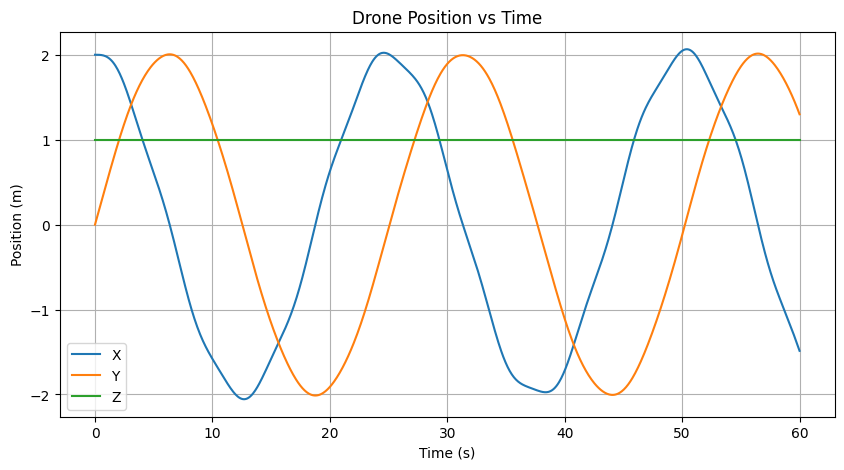

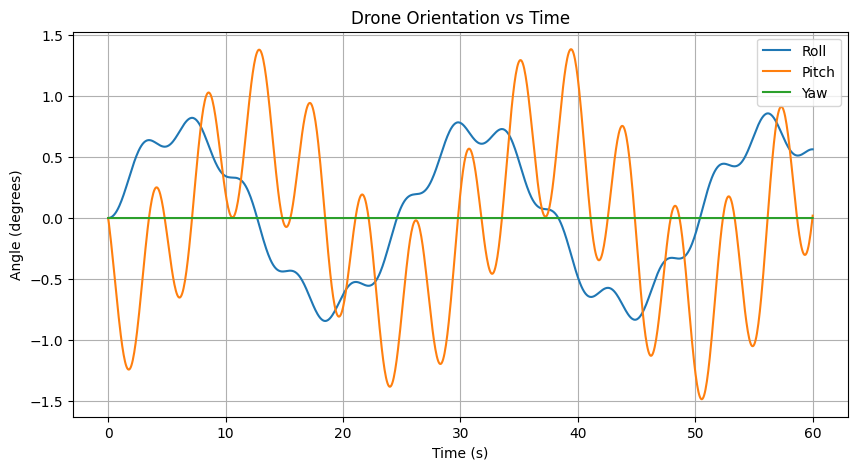

In [45]:
plt.figure(figsize=(10,5))
plt.plot(sol_q2.t, sol_q2.y[0], label="X")
plt.plot(sol_q2.t, sol_q2.y[1], label="Y")
plt.plot(sol_q2.t, sol_q2.y[2], label="Z")

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Drone Position vs Time")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(sol_q2.t, np.rad2deg(sol_q2.y[6]), label="Roll")
plt.plot(sol_q2.t, np.rad2deg(sol_q2.y[7]), label="Pitch")
plt.plot(sol_q2.t, np.rad2deg(sol_q2.y[8]), label="Yaw")

plt.xlabel("Time (s)")
plt.ylabel("Angle (degrees)")
plt.title("Drone Orientation vs Time")
plt.legend()
plt.grid()
plt.show()

#Question 3

In [46]:
import numpy as np

t_takeoff = 3.0
t_hover1 = 2.0
t_yaw = 2.0
t_hover2 = 2.0

t_move1 = 5.0
t_move2 = 5.0

t_land = 100.0

t1 = t_takeoff
t2 = t1 + t_hover1
t3 = t2 + t_move1
t4 = t3 + t_hover1
t5 = t4 + t_yaw
t6 = t5 + t_move2
t7 = t6 + t_hover2
t8 = t7 + t_land

def situation3(t):

    if t <= t1:
        x = 0
        y = 0
        z = t/t_takeoff
        psi = 0

    elif t <= t2:
        x = 0
        y = 0
        z = 1
        psi = 0

    elif t <= t3:
        x = (t-t2)/t_move1 * 5
        y = 0
        z = 1
        psi = 0

    elif t <= t4:
        x = 5
        y = 0
        z = 1
        psi = 0

    elif t <= t5:
        x = 5
        y = 0
        z = 1
        psi = (t-t4)/t_yaw * (np.pi/2)

    elif t <= t6:
        x = 5
        y = (t-t5)/t_move2 * 5
        z = 1
        psi = np.pi/2

    elif t <= t7:
        x = 5
        y = 5
        z = 1
        psi = np.pi/2

    elif t <= t8:
        x = 5
        y = 5
        z = 1 - (t-t7)/t_land
        psi = np.pi/2
    else:
        x = 5
        y = 5
        z = 0
        psi = np.pi/2

    return x, y, z, psi


t = np.linspace(0, t8, 1500)

x, y, z, psi = np.array([
    situation3(time) for time in t]).T


In [47]:
def situation3_full(t):
  x, y, z, psi = situation3(t)

  if t <= t1:
    vx, vy, vz = 0.0, 0.0, 1.0 / t_takeoff
  elif t <= t2:
    vx, vy, vz = 0.0, 0.0, 0.0
  elif t <= t3:
    vx, vy, vz = 5.0 / t_move1, 0.0, 0.0
  elif t <= t4:
    vx, vy, vz = 0.0, 0.0, 0.0
  elif t <= t5:
    vx, vy, vz = 0.0, 0.0, 0.0
  elif t <= t6:
    vx, vy, vz = 0.0, 5.0 / t_move2, 0.0
  elif t <= t7:
    vx, vy, vz = 0.0, 0.0, 0.0
  elif t <= t8:
    vx, vy, vz = 0.0, 0.0, -1.0 / t_land
  else:
    vx, vy, vz = 0.0, 0.0, 0.0

  ax, ay, az = 0.0, 0.0, 0.0
  return x, y, z, vx, vy, vz, ax, ay, az, psi

In [48]:
def position_controller_q3(state, t):
  x, y, z = state[0:3]
  vx, vy, vz = state[3:6]

  xd, yd, zd, vxd, vyd, vzd, axd, ayd, azd, psi_des = situation3_full(t)

  ax_cmd = axd + Kp_pos * (xd - x) + Kd_pos * (vxd - vx)
  ay_cmd = ayd + Kp_pos * (yd - y) + Kd_pos * (vyd - vy)
  az_cmd = azd + Kp_pos * (zd - z) + Kd_pos * (vzd - vz)

  return ax_cmd, ay_cmd, az_cmd, psi_des


def drone_dynamics_q3(t, state):
  x, y, z = state[0:3]
  vx, vy, vz = state[3:6]
  phi, theta, psi = state[6:9]
  phidot, thetadot, psidot = state[9:12]

  ax_cmd, ay_cmd, az_cmd, psi_des = position_controller_q3(state, t)

  T_des = m * (az_cmd + g) / (np.cos(phi) * np.cos(theta))
  phi_des = (ax_cmd * np.sin(psi) - ay_cmd * np.cos(psi)) / g
  theta_des = (ax_cmd * np.cos(psi) + ay_cmd * np.sin(psi)) / g

  phi_des = np.clip(phi_des, -np.deg2rad(25), np.deg2rad(25))
  theta_des = np.clip(theta_des, -np.deg2rad(25), np.deg2rad(25))

  tau_x = (phi_des - phi) - phidot
  tau_y =(theta_des - theta) - thetadot
  tau_z =  (psi_des - psi) -  psidot

  O1, O2, O3, O4 = rotor_mixer(T_des, tau_x, tau_y, tau_z)

  L1 = kf * O1**2
  L2 = kf * O2**2
  L3 = kf * O3**2
  L4 = kf * O4**2
  L_tot = L1 + L2 + L3 + L4

  tau_x_act = arm * (L2 - L4)
  tau_y_act = arm * (L3 - L1)
  tau_z_act = km * (O1**2 - O2**2 + O3**2 - O4**2)

  dx = vx
  dy = vy
  dz = vz

  vdx = (L_tot / m) * (
      np.cos(phi) * np.sin(theta) * np.cos(psi) + np.sin(phi) * np.sin(psi)
  )
  vdy = (L_tot / m) * (
      np.cos(phi) * np.sin(theta) * np.sin(psi) - np.sin(phi) * np.cos(psi)
  )
  vdz = (L_tot / m) * (np.cos(phi) * np.cos(theta)) - g

  phidot = phidot + thetadot * np.sin(phi) * np.tan(theta) + psidot * np.cos(phi) * np.tan(theta)
  thetadot = thetadot * np.cos(phi) - psidot * np.sin(phi)
  psidot = (thetadot * np.sin(phi) + psidot * np.cos(phi)) / np.cos(theta)

  dp = (tau_x_act + (Iyy - Izz) * thetadot * psidot) / Ixx
  dq = (tau_y_act + (Izz - Ixx) * phidot * psidot) / Iyy
  dr = (tau_z_act + (Ixx - Iyy) * phidot * thetadot) / Izz

  return [dx, dy, dz, vdx, vdy, vdz, phidot, thetadot, psidot, dp, dq, dr]


state0_q3 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

t_eval_q3 = np.linspace(0, t8, 2000)
sol_q3 = solve_ivp(
    drone_dynamics_q3, (0, t8), state0_q3, t_eval=t_eval_q3, max_step=0.05
)

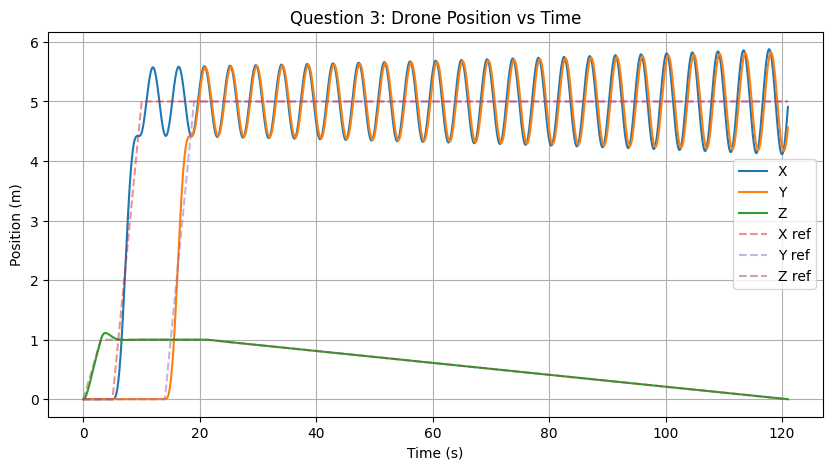

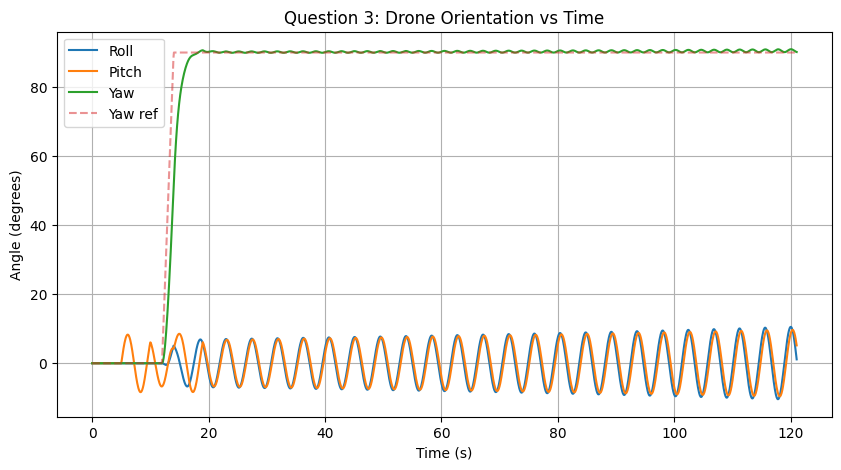

Max descent speed during landing: 0.01209 m/s


In [49]:
plt.figure(figsize=(10, 5))
plt.plot(sol_q3.t, sol_q3.y[0], label="X")
plt.plot(sol_q3.t, sol_q3.y[1], label="Y")
plt.plot(sol_q3.t, sol_q3.y[2], label="Z")
plt.plot(t, x, "--", alpha=0.5, label="X ref")
plt.plot(t, y, "--", alpha=0.5, label="Y ref")
plt.plot(t, z, "--", alpha=0.5, label="Z ref")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Question 3: Drone Position vs Time")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(sol_q3.t, np.rad2deg(sol_q3.y[6]), label="Roll")
plt.plot(sol_q3.t, np.rad2deg(sol_q3.y[7]), label="Pitch")
plt.plot(sol_q3.t, np.rad2deg(sol_q3.y[8]), label="Yaw")
plt.plot(t, np.rad2deg(psi), "--", alpha=0.5, label="Yaw ref")
plt.xlabel("Time (s)")
plt.ylabel("Angle (degrees)")
plt.title("Question 3: Drone Orientation vs Time")
plt.legend()
plt.grid()
plt.show()

vz_landing = sol_q3.y[5, sol_q3.t >= t7]
print(f"Max descent speed during landing: {np.max(np.abs(vz_landing)):.5f} m/s")